In [1]:
import pandas as pd

# Load the Student Performance dataset
df = pd.read_csv("student-mat.csv", sep=";")

# Display the first 5 rows
display(df.head())

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# Dataset mein total rows aur columns
print("Dataset shape:", df.shape)

# Saare column names
print("\nColumn names:")
print(df.columns.tolist())

# Har column ka data type
print("\nData types:")
print(df.dtypes)

# Missing values check karo
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate rows check karo
print("\nDuplicate rows:", df.duplicated().sum())

# Numerical data ka summary
display(df.describe())

Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types:
school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Final grade counts:
G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64


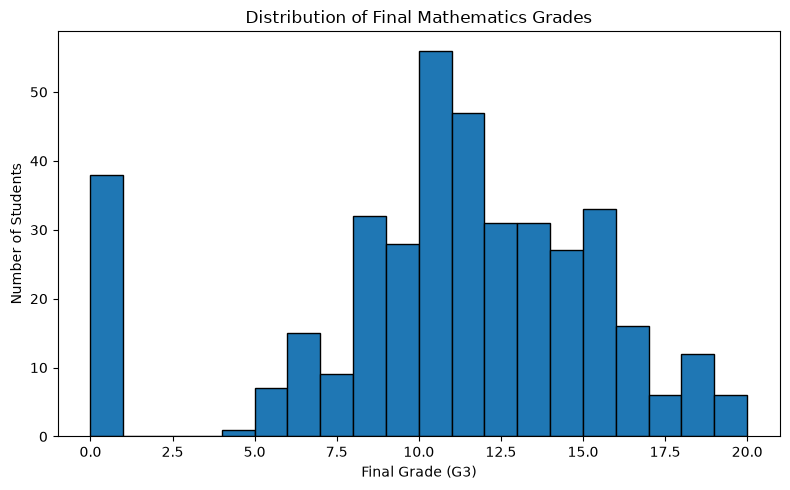

In [3]:
# Final Mathematics grade (G3) ka distribution
print("Final grade counts:")
print(df["G3"].value_counts().sort_index())

# Grades ka histogram
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=20, edgecolor="black")
plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [4]:
# Input features: student ki information
# G1 aur G2 ko hata rahe hain, taaki pehle ke grades par
# prediction depend na kare.
X = df.drop(columns=["G1", "G2", "G3"])

# Target: final Mathematics grade
y = df["G3"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget values:")
display(y.head())

Features shape: (395, 30)
Target shape: (395,)

Input features:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,yes,no,no,4,3,4,1,1,3,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,yes,no,5,3,3,1,1,3,4
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,yes,no,4,3,2,2,3,3,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,yes,3,2,2,1,1,5,2
4,GP,F,16,U,GT3,T,3,3,other,other,...,yes,no,no,4,3,2,1,2,5,4



Target values:


0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training target records:", len(y_train))
print("Testing target records:", len(y_test))

Training records: 316
Testing records: 79
Training target records: 316
Testing target records: 79


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical aur categorical columns identify karo
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical columns: missing values fill + scaling
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns: missing values fill + encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Dono pipelines combine karo
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing setup complete!")

Numerical features: 13
Categorical features: 17
Preprocessing setup complete!


/tmp/ipykernel_51759/806461886.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Linear Regression
linear_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

# Model 2: Random Forest Regressor
random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

# Train both models
linear_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")
print("Random Forest trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!


In [11]:
import numpy as np

In [12]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Dono models se predictions
linear_predictions = linear_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

# Model evaluation function
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

# Dono models ke results
linear_results = evaluate_model(y_test, linear_predictions)
rf_results = evaluate_model(y_test, rf_predictions)

# Comparison table
results_df = pd.DataFrame([
    {"Model": "Linear Regression", **linear_results},
    {"Model": "Random Forest", **rf_results}
])

display(results_df.round(3))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,3.395,17.604,4.196,0.141
1,Random Forest,2.994,14.069,3.751,0.314


In [13]:
comparison_df = pd.DataFrame({
    "Actual Grade": y_test.to_numpy(),
    "Linear Regression": np.round(linear_predictions, 2),
    "Random Forest": np.round(rf_predictions, 2)
})

display(comparison_df.head(15))

,Actual Grade,Linear Regression,Random Forest
0,10,1.89,9.57
1,12,7.45,9.32
2,5,8.31,10.20
3,10,11.55,12.14
4,9,10.20,9.90
5,13,9.43,8.99
6,18,13.21,14.68
7,6,12.69,11.36
8,0,10.27,10.20
9,14,12.34,12.21


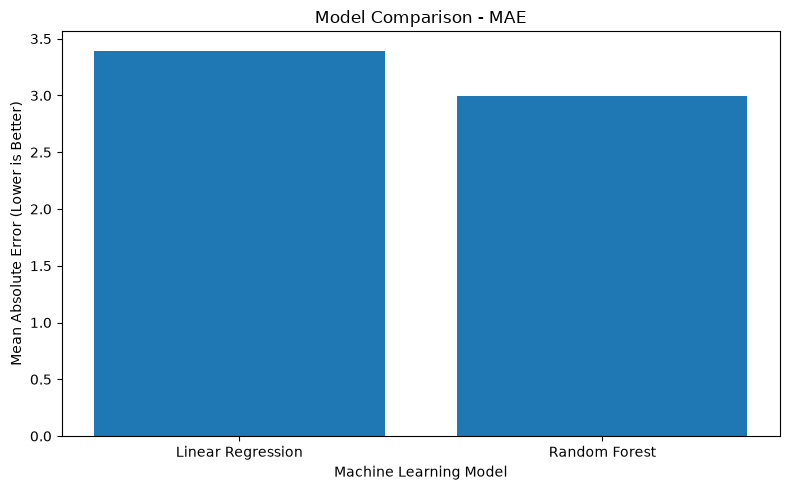

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["MAE"])

plt.title("Model Comparison - MAE")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Absolute Error (Lower is Better)")

plt.tight_layout()
plt.show()

In [15]:
results_df.to_csv("week3_model_comparison.csv", index=False)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [17]:
import joblib

# Dono trained models save karo
joblib.dump(linear_model, "week3_linear_regression.pkl")
joblib.dump(random_forest_model, "week3_random_forest.pkl")

print("Both trained models saved successfully!")

Both trained models saved successfully!


# Week 3: Machine Learning Model Development

## Objective
Predict students' final Mathematics grades (G3) using machine learning.

## Dataset
Student Performance Dataset — Mathematics (`student-mat.csv`).

## Models Used
- Linear Regression
- Random Forest Regressor

## Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score

## Results
Random Forest performed better than Linear Regression on the current test set.

- Linear Regression: MAE = 3.395, RMSE = 4.196, R² = 0.141
- Random Forest: MAE = 2.994, RMSE = 3.751, R² = 0.314

## Conclusion
Random Forest achieved lower prediction errors and a higher R² score than Linear Regression on this test split. However, the R² score indicates that prediction performance still has room for improvement.

## Dataset Source
UCI Student Performance Dataset:
https://archive.ics.uci.edu/dataset/320/student+performance